# ЛР3. Анализ результатов

С. Д. Кузнецов, ИУ6-55Б. Можно ли доверять LLM в задачах классического машинного обучения.

In [1]:
import json
import sys
from pathlib import Path
from itertools import combinations

ROOT = Path.cwd()
if not (ROOT / 'tasks.jsonl').exists():
    ROOT = ROOT.parent
if (ROOT / '.runtime').exists():
    sys.path.insert(0, str(ROOT / '.runtime'))
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
import lab
import notebook_analysis as view

SEED = 42
N_BOOT = 1000
MODELS = ['gigachat', 'yandex', 'foreign', 'local']
NAMES = view.model_names()
TYPES = ['A', 'B', 'C', 'D', 'F']
TABLES = ROOT / 'results' / 'tables'
FIGURES = ROOT / 'figures'
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False})

def show_table(table, name):
    table.to_csv(TABLES / f'{name}.csv', index=False, encoding='utf-8-sig')
    display(table)

def show_figure(fig, name):
    fig.savefig(FIGURES / f'{name}.png', dpi=180, bbox_inches='tight')
    from IPython.display import Image
    display(Image(filename=str(FIGURES / f'{name}.png')))
    plt.close(fig)

def boot_ci(values, n=N_BOOT, seed=SEED):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    samples = values[rng.integers(0, len(values), (n, len(values)))]
    return np.percentile(samples.mean(axis=1), [2.5, 97.5])

def fmt_ci(row):
    return f"{row['accuracy']:.0%} [{row['ДИ 2.5%']:.0%}; {row['ДИ 97.5%']:.0%}]"

## 1. Данные

Банк: 36 задач A/B/C/D/F и отдельный опыт E. Пять пилотных задач не входят в оценку.
Источник — сохранённые ответы из `data/analysis_responses.jsonl` или полного локального журнала. Новые запросы к моделям не выполняются.
A/B/F оцениваются по эталону. Для C и D два проверяющих работали
в отдельных сессиях с общей рубрикой. Им дали анонимные ответы и факты
первого запуска кода D. Названия моделей, прежние баллы и оценки другой сессии им не передавали.
«Проверяющий 1» и «Проверяющий 2» обозначают эти сессии для C/D.
Баллы за объяснения B взяты из прежних вспомогательных бланков.
Для C accuracy рассчитывается по итоговым зачётам автора в
`data/c_final_decisions.csv`. Баллы, согласованность и зачёт по рубрике
показываются по бланкам проверяющих. Для D оба проверяющих должны
подтвердить запуск, вывод метрики в допуске и соблюдение методики.

In [2]:
bundle = view.load_results()
if bundle['evaluation_mode'] != 'independent_ai_review':
    raise ValueError(bundle['manual_note'] or 'Не найдены оба бланка независимой проверки C/D.')
bank = bundle['tasks']
scores = bundle['scores']
ok = view.task_matrix(bundle)
show_table(view.coverage(bundle), 'coverage')
display(ok)
inventory = pd.crosstab(bank.loc[bank.type.ne('E'), 'topic'],
                        bank.loc[bank.type.ne('E'), 'type']).reindex(columns=TYPES, fill_value=0)
inventory['Всего'] = inventory.sum(axis=1)
show_table(inventory.reset_index(), 'bank_topics')

,модель,часть,получено,ожидается,обрывов,статус
0,GigaChat-2-Max,Банк A/B/C/D/F,36,36,0,ответы получены
1,GigaChat-2-Max,E: 0/5/20,300,300,1,ответы получены
2,Alice AI LLM,Банк A/B/C/D/F,36,36,0,ответы получены
3,Alice AI LLM,E: 0/5/20,300,300,0,ответы получены
4,GPT-OSS 120B · Groq,Банк A/B/C/D/F,36,36,0,ответы получены
5,GPT-OSS 120B · Groq,E: 0/5/20,300,300,0,ответы получены
6,Qwen3 4B · локально,Банк A/B/C/D/F,36,36,6,ответы получены
7,Qwen3 4B · локально,E: 0/5/20,300,300,118,ответы получены


model,GigaChat-2-Max,Alice AI LLM,GPT-OSS 120B · Groq,Qwen3 4B · локально
task_id,,,,
A01,True,True,True,True
A02,True,False,True,True
A03,True,False,True,True
A04,True,True,True,True
A05,True,True,False,True
A06,True,True,True,True
A07,True,True,True,True
A08,False,True,True,True
B01,True,True,True,True


type,topic,A,B,C,D,F,Всего
0,PCA,1,1,0,0,1,3
1,PCA и логистическая регрессия,0,0,0,1,0,1
2,PCA и регрессия,0,0,1,0,0,1
3,SVM,1,0,0,1,2,4
4,SVM и деревья,0,1,0,0,0,1
5,kNN,1,0,0,1,1,3
6,Байесовские методы,1,1,1,0,1,4
7,Деревья и ансамбли,1,0,0,0,1,2
8,Деревья и метрики,0,0,0,1,0,1
9,Кластеризация,1,1,1,0,1,4


In [3]:
display(bank.loc[bank['id'].isin(['A01', 'C02', 'D03', 'F07']), ['id', 'type', 'text_ru', 'reference']])

,id,type,text_ru,reference
0,A01,A,"Дефект есть у 1% деталей. Чувствительность датчика 95%, вероятность срабатывания без дефекта 5%....",0.161
15,C02,C,В 100000 измерениях станка только 0.5% отказов. Пропуск отказа дорог. Нужно сравнить простую мод...,"PR-AUC, стоимость/recall, порог по validation, временное разбиение"
21,D03,D,"Сгенерируйте make_classification(n_samples=1500,n_features=10,n_informative=5,n_redundant=2,weig...","{'implementation': 'reference_d.py::D03', 'metric_atol': 0.03}"
30,F07,F,У бинарного классификатора accuracy=0.9 на 1000 объектах. Найдите precision положительного класс...,INSUFFICIENT_DATA


## 2. Методика: идентификаторы моделей и даты запросов по сохранённому журналу

In [4]:
meta = view.model_metadata(bundle)
show_table(meta, 'models')
show_table(view.protocol_timeline(bundle), 'protocol_timeline')
print('Системный промпт:')
print(lab.config()['system_prompt'])
print('Прогноз: H1 — подтвердится; H5 — подтвердится; H10 — подтвердится.')

,модель,заданный ID,ID в ответе,версия / fingerprint,temperature,первый запрос UTC,последний запрос UTC,ответов bank+E
0,GigaChat-2-Max,GigaChat-2-Max,GigaChat-2-Max:2.0.28.2,API не сообщает,0.0,2026-11-18T23:01:52.763437+00:00,2026-11-18T23:55:07.449368+00:00,336
1,Alice AI LLM,gpt://{folder_id}/aliceai-llm/latest,gpt://{folder_id}/aliceai-llm/latest,gpt://aliceai-llm/latest,0.0,2026-11-18T23:01:57.917671+00:00,2026-11-19T00:14:08.944597+00:00,336
2,GPT-OSS 120B · Groq,openai/gpt-oss-120b,openai/gpt-oss-120b,fp_02b0d31eca; fp_05e76be18c; fp_19b184c447; fp_245acb052a; fp_267e812a3a; fp_27194a498a; fp_420...,0.0,2026-11-18T23:02:03.101666+00:00,2026-11-19T07:01:49.962014+00:00,336
3,Qwen3 4B · локально,qwen3:4b,qwen3:4b,359d7dd4bcdab3d86b87d73ac27966f4dbb9f5efdfcc75d34a8764a09474fae7,0.0,2026-11-18T23:02:04.402038+00:00,2026-11-19T03:15:08.244098+00:00,336


,этап,время UTC,источник
0,Коммит гипотез и предварительного прогноза,2026-11-18T23:01:34+00:00,Git 731d25d
1,Фиксация хэшей протокола,2026-11-18T23:01:36.614810+00:00,data/preregistration.lock.json
2,Первый оценочный запрос,2026-11-18T23:01:52.763437+00:00,data/responses.jsonl


Системный промпт:
/no_think
Реши задачу по машинному обучению самостоятельно. Не используй внешние инструменты. Дай краткое проверяемое обоснование не более 100 слов, затем итог. Не повторяй условие и инструкции. Не дополняй условие неуказанными данными. Если данных недостаточно, так и ответь. Для задания на код не пиши обоснование: выдай исполняемый код внутри ровно одного Markdown-блока с открывающей строкой ```python и закрывающей строкой ```. После обоснования или закрывающего маркера блока кода заверши ответ ровно двумя строками:
ОТВЕТ: <JSON-число, JSON-массив чисел, true/false, метка, либо строка>
УВЕРЕННОСТЬ: <целое число от 0 до 100>
Прогноз: H1 — подтвердится; H5 — подтвердится; H10 — подтвердится.


In [5]:
print('Зафиксированные хэши протокола:')
display(bundle['protocol'])

Зафиксированные хэши протокола:


{'created_at': '2026-11-18T23:01:36.614810+00:00',
 'git_commit': '731d25ddc60ecd0d8e9df29de541a8d8410b108e',
 'hashes': {'tasks.jsonl': '91a96fab56270e670dfbbd99daa8ba035ec87e6f61a63c2bba4491b8bf078f2a',
  'pilots.jsonl': 'fdf040258e1f6601d388e2553ae4a794991bbbb491450184991d956a23ba8b0b',
  'models.json': '5981375459844749d86afe068a8a16d754db09a4056f6970e44c5041592fe1d2',
  'preregistration.md': '85f242e6d63c474c4e7519c706938f7a991e27f37b95c46efc7429f9f0ff968e',
  'rubrics.md': '6310529f7074578cdf2871c87ef35d140e21a8f1aec4381aeb3adb1f0f5d426c',
  'bank.py': '23944acad58315dc16509332e90418788bf17bc8454067aecae56074b098751f',
  'reference_d.py': 'dbc9708e977334b7fce5df6f5870436ab8ef8fb8a8317f00ab7f13d7019cc181',
  'lab.py': '68f0522fdff9e40a30baba2625a22505e45b8d1923b149c12b4f360a7eecb2dd',
  'local/Qwen3-4B-nothink.Modelfile': '76eb5b52f98b6549e64c60c264bc3509809e1d20c9cebbfc76f9b892b1ea4e07',
  'local/Qwen3-4B-nothink.template.txt': '6c5bfa3dc408f5fed7f3efc27498a8837cbed3ab983be7fcc6b

## 3. Точность с 95% доверительными интервалами

Интервалы — процентильный бутстреп по задачам, 1000 повторов, seed=42.
В дополнение сохраняются кластерные интервалы для связанных задач A/F.
Общая точность использует строгий критерий C/D из раздела 1; E в неё не входит.

In [6]:
accuracy = view.accuracy_table(bundle)
acc_table = accuracy.assign(значение=accuracy.apply(fmt_ci, axis=1)).pivot(
    index='модель', columns='тип', values='значение').reindex(
    index=[NAMES[m] for m in MODELS], columns=['Все 36', *TYPES])
show_table(acc_table.reset_index(), 'accuracy_ci')
show_table(accuracy, 'accuracy_long')

тип,модель,Все 36,A,B,C,D,F
0,GigaChat-2-Max,75% [58%; 89%],88% [62%; 100%],100% [100%; 100%],20% [0%; 60%],100% [100%; 100%],67% [42%; 92%]
1,Alice AI LLM,64% [47%; 81%],75% [38%; 100%],100% [100%; 100%],20% [0%; 60%],0% [0%; 0%],83% [58%; 100%]
2,GPT-OSS 120B · Groq,89% [78%; 97%],88% [62%; 100%],100% [100%; 100%],60% [20%; 100%],100% [100%; 100%],92% [75%; 100%]
3,Qwen3 4B · локально,75% [61%; 89%],100% [100%; 100%],100% [100%; 100%],40% [0%; 80%],0% [0%; 0%],92% [75%; 100%]


,модель,тип,оценено,всего,accuracy,ДИ 2.5%,ДИ 97.5%,кластерный ДИ 2.5%,кластерный ДИ 97.5%,статус,оценивание C/D
0,GigaChat-2-Max,Все 36,36,36,0.7500,0.5833,0.8889,0.5897,0.8889,готово,Проверяющий 1 / Проверяющий 2
1,GigaChat-2-Max,A,8,8,0.8750,0.6250,1.0000,0.6250,1.0000,готово,Проверяющий 1 / Проверяющий 2
2,GigaChat-2-Max,B,6,6,1.0000,1.0000,1.0000,1.0000,1.0000,готово,Проверяющий 1 / Проверяющий 2
3,GigaChat-2-Max,C,5,5,0.2000,0.0000,0.6000,0.0000,0.6000,готово,Проверяющий 1 / Проверяющий 2
4,GigaChat-2-Max,D,5,5,1.0000,1.0000,1.0000,1.0000,1.0000,готово,Проверяющий 1 / Проверяющий 2
5,GigaChat-2-Max,F,12,12,0.6667,0.4167,0.9167,0.4167,0.9167,готово,Проверяющий 1 / Проверяющий 2
6,Alice AI LLM,Все 36,36,36,0.6389,0.4722,0.8056,0.4706,0.7778,готово,Проверяющий 1 / Проверяющий 2
7,Alice AI LLM,A,8,8,0.7500,0.3750,1.0000,0.3750,1.0000,готово,Проверяющий 1 / Проверяющий 2
8,Alice AI LLM,B,6,6,1.0000,1.0000,1.0000,1.0000,1.0000,готово,Проверяющий 1 / Проверяющий 2
9,Alice AI LLM,C,5,5,0.2000,0.0000,0.6000,0.0000,0.6000,готово,Проверяющий 1 / Проверяющий 2


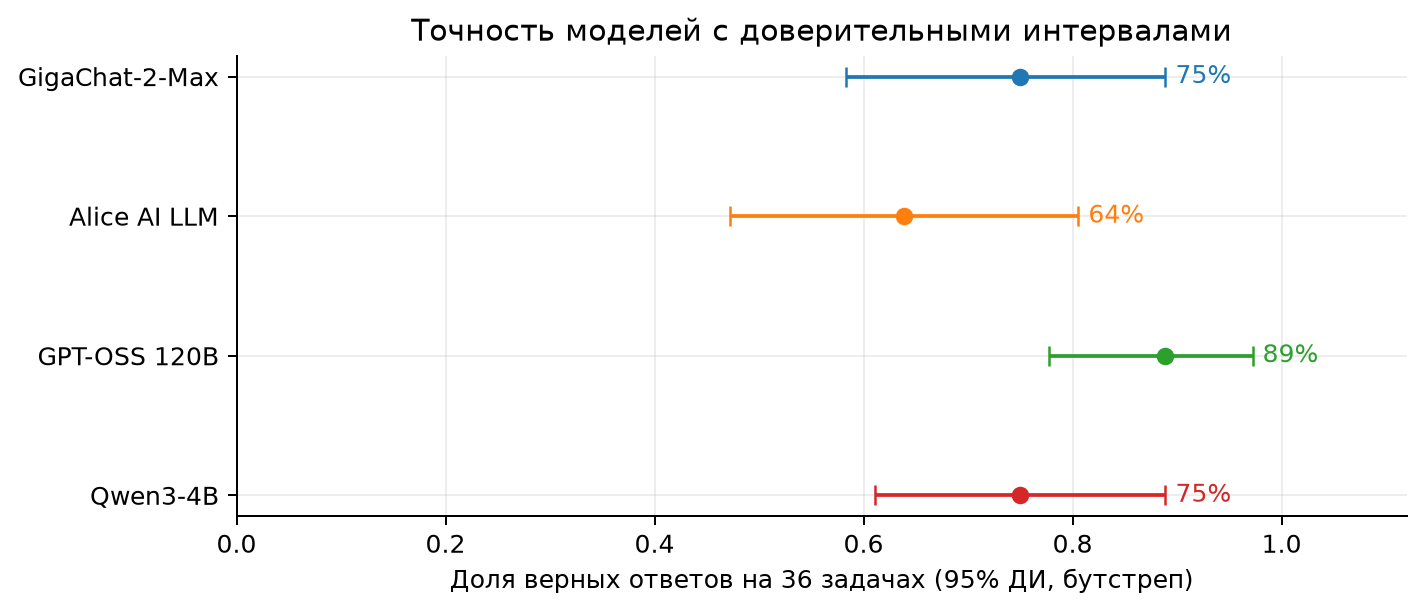

In [7]:
show_figure(view.plot_accuracy(accuracy), 'accuracy_ci')

## 4. Тепловая карта

На основной карте A/B/F — доля верных ответов, C — доля итоговых зачётов автора,
D — доля полностью корректных программ, E — balanced accuracy при 20 примерах.
На дополнительной карте C — средний балл двух проверяющих, делённый на 2.

тип,модель,A,B,C,D,F,E
0,GigaChat-2-Max,0.875,1.0,0.2,1.0,0.6667,0.7038
1,Alice AI LLM,0.750,1.0,0.2,0.0,0.8333,0.8492
2,GPT-OSS 120B · Groq,0.875,1.0,0.6,1.0,0.9167,0.8704
3,Qwen3 4B · локально,1.000,1.0,0.4,0.0,0.9167,0.2756


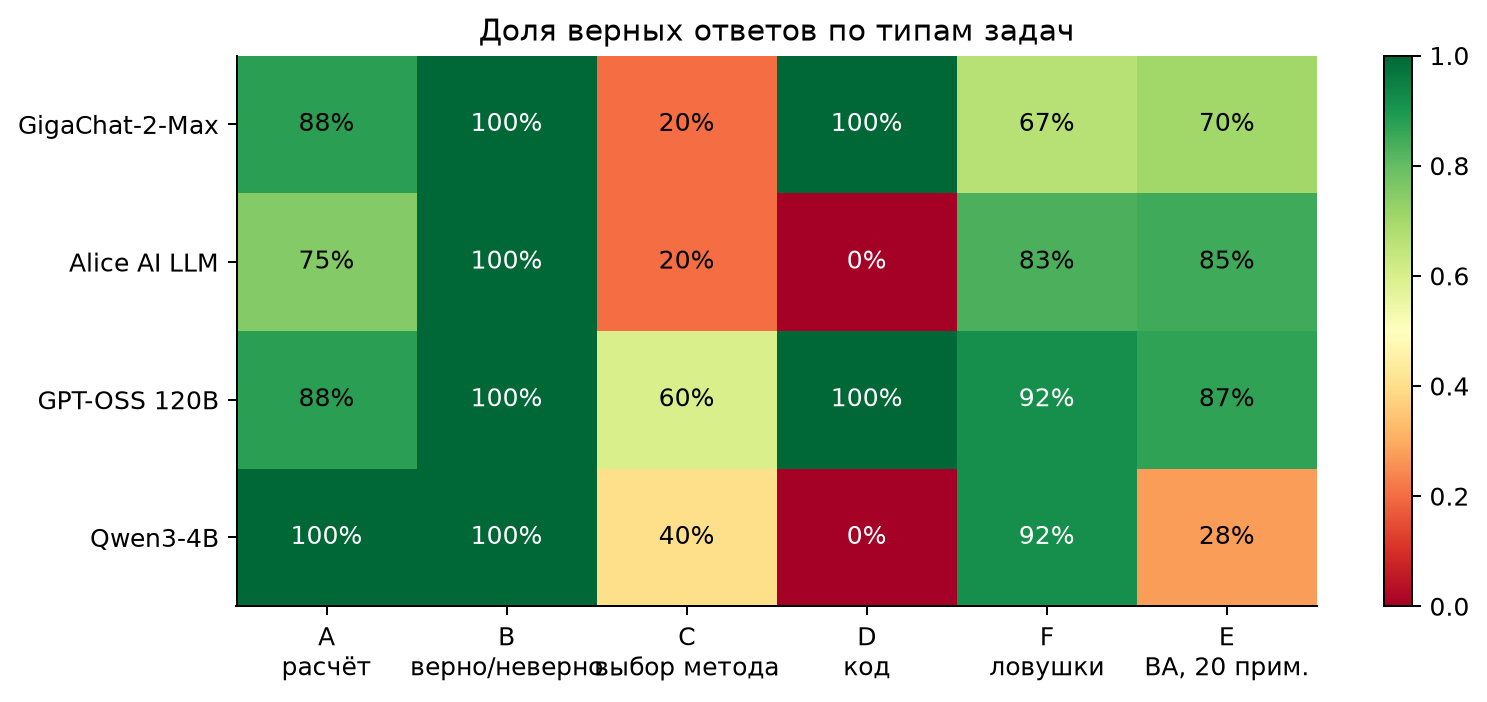

тип,модель,A,B,C,D,F,E
0,GigaChat-2-Max,0.875,1.0,0.5,1.0,0.6667,0.7038
1,Alice AI LLM,0.750,1.0,0.5,0.0,0.8333,0.8492
2,GPT-OSS 120B · Groq,0.875,1.0,0.5,1.0,0.9167,0.8704
3,Qwen3 4B · локально,1.000,1.0,0.5,0.0,0.9167,0.2756


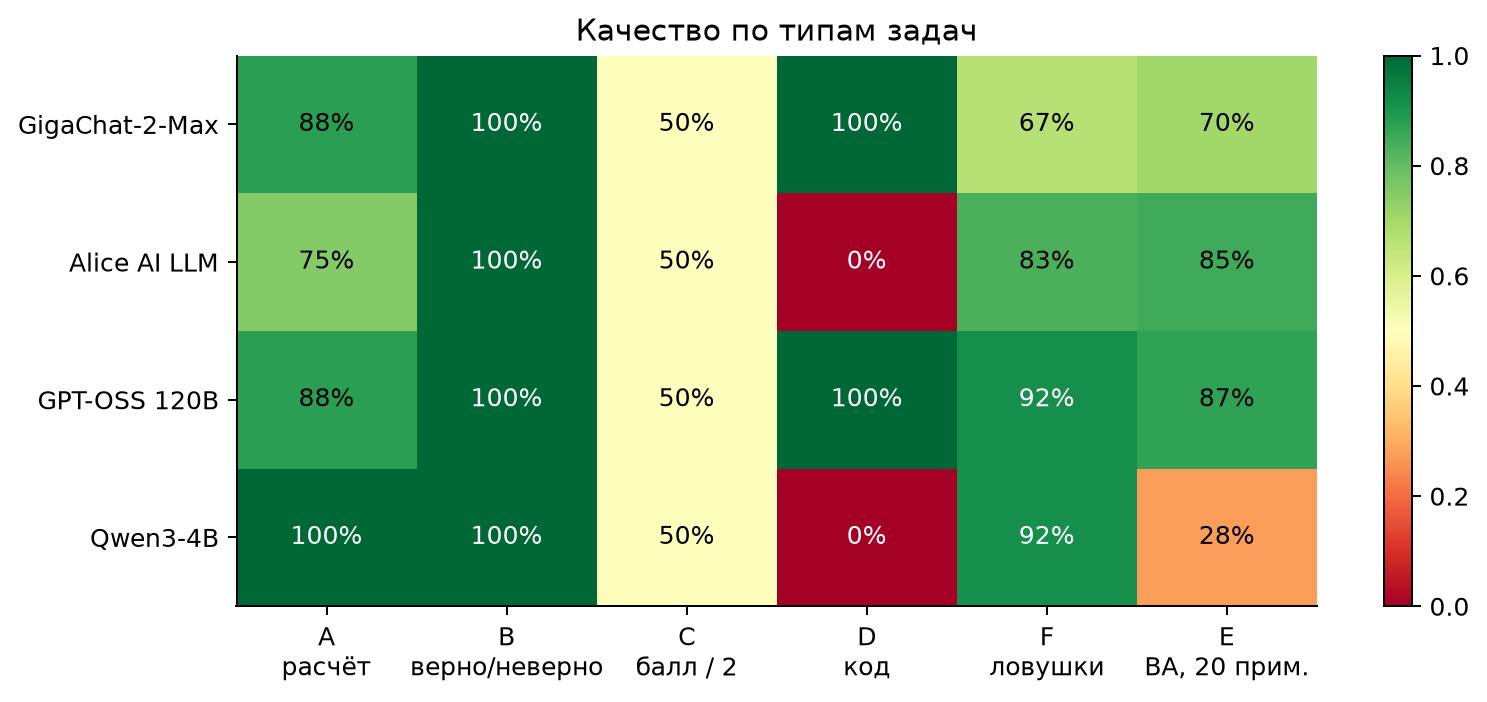

In [8]:
classification = view.classification_table(bundle)
rubric = view.rubric_summary(bundle)
strict_heat = view.heatmap_values(accuracy, classification)
show_table(strict_heat.reset_index(), 'heatmap_accuracy')
show_figure(view.plot_heatmap(accuracy, classification), 'heatmap_accuracy')
heat = view.heatmap_values(accuracy, classification, rubric)
show_table(heat.reset_index(), 'heatmap')
fig = view.plot_heatmap(accuracy, classification, rubric)
fig.axes[0].images[0].set_cmap('RdYlGn')
show_figure(fig, 'heatmap')

## 5. Тест Макнемара для всех пар моделей (36 задач, `exact=True`)

In [9]:
pairwise = view.pairwise_table(bundle)
show_table(pairwise, 'mcnemar')
print('Сравнение парное; дополнительно применена поправка Holm к шести p-значениям.')
print('Незначимость не доказывает равенство моделей.')

,model_a,model_b,n,both,only_a,only_b,neither,p,p_holm
0,GPT-OSS 120B · Groq,GigaChat-2-Max,36,25,7,2,2,0.1797,0.8984
1,GPT-OSS 120B · Groq,Qwen3 4B · локально,36,24,8,3,1,0.2266,0.9062
2,GPT-OSS 120B · Groq,Alice AI LLM,36,21,11,2,2,0.0225,0.1348
3,GigaChat-2-Max,Qwen3 4B · локально,36,21,6,6,3,1.0000,1.0000
4,GigaChat-2-Max,Alice AI LLM,36,18,9,5,4,0.4240,0.9062
5,Qwen3 4B · локально,Alice AI LLM,36,21,6,2,7,0.2891,0.9062


Сравнение парное; дополнительно применена поправка Holm к шести p-значениям.
Незначимость не доказывает равенство моделей.


## 6. Доля отказов («НЕЛЬЗЯ ОПРЕДЕЛИТЬ» или ответ не распознан)

In [10]:
refusals = view.response_quality(bundle)
show_table(refusals, 'refusals')
print('Оправданный отказ нужен в F07 и F08. Обрывы и отказы могут пересекаться.')

,модель,ответов,отказов (текст),отказов на F07/F08,отказов на остальных,не распознано ОТВЕТ,обрывов,покрытие уверенности
0,GigaChat-2-Max,36,2,2,0,0,0,1.0000
1,Alice AI LLM,36,2,2,0,0,0,1.0000
2,GPT-OSS 120B · Groq,36,2,2,0,0,0,1.0000
3,Qwen3 4B · локально,36,2,2,0,6,6,0.8056


Оправданный отказ нужен в F07 и F08. Обрывы и отказы могут пересекаться.


## 7. Код (тип D): запускаемость, корректность, методологические ошибки

,модель,проверено,нужно,pass@1,полная корректность D,результат в допуске,методологических ошибок,статус
0,GigaChat-2-Max,5,5,1.0,1.0,1.0,0.0,готово
1,Alice AI LLM,5,5,1.0,0.0,0.0,0.0,готово
2,GPT-OSS 120B · Groq,5,5,1.0,1.0,1.0,0.0,готово
3,Qwen3 4B · локально,5,5,0.0,0.0,0.0,NaN,готово


,sample_id,task_id,execution,pass1_observed,returncode,timed_out,elapsed_s,reference_metric,last_stdout_number_candidate
0,3f60376ecefb0cd8,D01,completed,1,0.0,False,2.2292,0.9825,0.9825
1,c72d92a6ba064533,D01,completed,1,0.0,False,2.1841,0.9825,NaN
2,c3d9d11ba953ac15,D01,completed,1,0.0,False,2.1173,0.9825,0.9825
3,7aa90cf7badca02d,D01,not_executable,0,NaN,NaN,NaN,0.9825,NaN
4,099eec2554cadbd9,D02,completed,1,0.0,False,2.0600,53.6263,53.6263
5,9f61930a9fc74c60,D02,completed,1,0.0,False,2.1820,53.6263,NaN
6,993edf0e03d063c6,D02,completed,1,0.0,False,2.0258,53.6263,53.6263
7,a65950ef457bfc3c,D02,not_executable,0,NaN,NaN,NaN,53.6263,NaN
8,79d598240aa001d4,D03,completed,1,0.0,False,2.3314,0.7404,0.7404
9,6208ea8200e8a98f,D03,completed,1,0.0,False,2.2990,0.7404,NaN


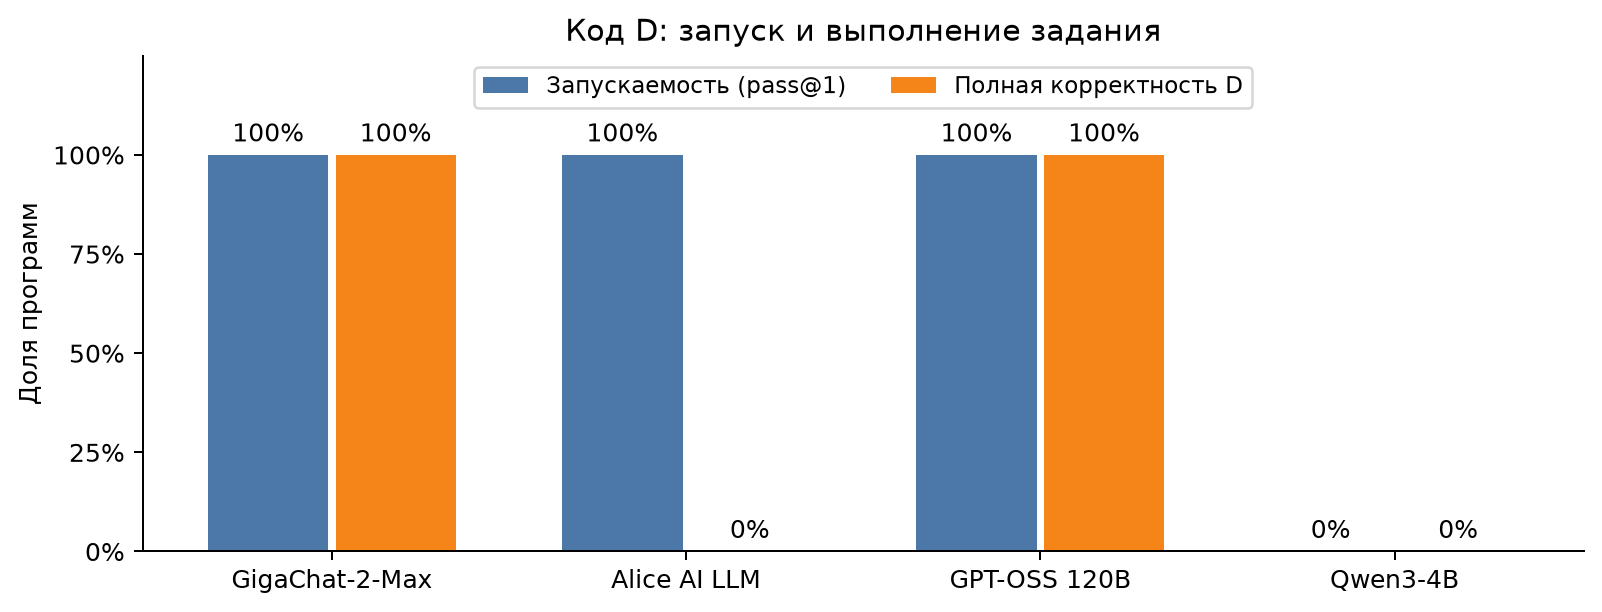

Используются первые сохранённые запуски в Docker; код моделей здесь не выполняется.
15 из 20 программ выполнились, 5 ответов оборваны. Пустой stdout не засчитывается как вывод метрики.


In [11]:
code_metrics = view.code_metrics(bundle)
show_table(code_metrics, 'code_metrics')
show_table(view.code_observations(), 'code_execution')
show_figure(view.plot_code_quality(code_metrics), 'code_quality')
print('Используются первые сохранённые запуски в Docker; код моделей здесь не выполняется.')
print('15 из 20 программ выполнились, 5 ответов оборваны. Пустой stdout не засчитывается как вывод метрики.')

## 8. Согласие двух проверяющих (каппа Коэна) и баллы по рубрике 0–2 для B и C

Процедура получения двух наборов оценок описана в разделе 1.
Для C и D показана κ по оценкам до обсуждения расхождений.
Если первый раунд C дал κ ниже 0,6, границу 0/1 уточнили и повторили слепую
оценку всех ответов C. Критерий полного балла сохранился.
Строка B отражает прежние вспомогательные оценки объяснений.

In [12]:
print('Критерий полного зачёта D: pass@1 ∧ result_ok ∧ ¬methodology_error')
print('Первая попытка сохранена в data/code_execution.json; повторный запуск не выбирается по качеству.')

Критерий полного зачёта D: pass@1 ∧ result_ok ∧ ¬methodology_error
Первая попытка сохранена в data/code_execution.json; повторный запуск не выбирается по качеству.


In [13]:
agreement = view.reviewer_summary(bundle)
show_table(agreement, 'agreement')
c_agreement = bundle['agreement']['C']
print(f"Каппа C в первом раунде: {c_agreement['first_kappa']:.3f}.")
if c_agreement['kappa'] is None:
    print('Повторный раунд C: все выставленные баллы одинаковы, поэтому κ не определена.')
else:
    print(f"Каппа C в повторном раунде: {c_agreement['kappa']:.3f}.")
rubric = view.rubric_summary(bundle)
show_table(rubric, 'rubric')
c_details = scores.loc[scores.type.eq('C'),
    ['model', 'task_id', 'score_1', 'score_2', 'manual_correct', 'correct']].rename(
    columns={'model': 'модель', 'task_id': 'задача', 'score_1': 'Проверяющий 1',
             'score_2': 'Проверяющий 2', 'manual_correct': 'зачёт по двум оценкам',
             'correct': 'итоговый зачёт C'})
c_details['модель'] = c_details['модель'].map(NAMES)
show_table(c_details, 'c_review_details')

,тип,ответов,Проверяющий 1,Проверяющий 2,доля совпадений,каппа Коэна
0,B,24,1.9167,1.8333,0.9167,0.625
1,C,20,1.0000,1.0000,1.0000,NaN
2,D,20,1.2500,1.2500,1.0000,1.000


Каппа C в первом раунде: 0.419.
Повторный раунд C: все выставленные баллы одинаковы, поэтому κ не определена.


,модель,средний балл B (0–2),средний балл C (0–2)
0,GigaChat-2-Max,2.00,1.0
1,Alice AI LLM,2.00,1.0
2,GPT-OSS 120B · Groq,1.75,1.0
3,Qwen3 4B · локально,1.75,1.0


,модель,задача,Проверяющий 1,Проверяющий 2,зачёт по двум оценкам,итоговый зачёт C
56,GigaChat-2-Max,C01,1.0,1.0,False,False
57,Alice AI LLM,C01,1.0,1.0,False,True
58,GPT-OSS 120B · Groq,C01,1.0,1.0,False,True
59,Qwen3 4B · локально,C01,1.0,1.0,False,False
60,GigaChat-2-Max,C02,1.0,1.0,False,False
61,Alice AI LLM,C02,1.0,1.0,False,False
62,GPT-OSS 120B · Groq,C02,1.0,1.0,False,True
63,Qwen3 4B · локально,C02,1.0,1.0,False,False
64,GigaChat-2-Max,C03,1.0,1.0,False,False
65,Alice AI LLM,C03,1.0,1.0,False,False


## 9. Калибровка уверенности: ECE и диаграмма надёжности

Используются автоматически проверяемые A/B/F и только ответы с указанной уверенностью.
ECE — взвешенное среднее |средняя уверенность − доля правильных ответов| в пяти фиксированных интервалах.

,модель,ответов с уверенностью,всего A/B/F,покрытие,средняя уверенность,accuracy на том же подмножестве,ECE
0,GPT-OSS 120B · Groq,26,26,1.0000,0.9788,0.9231,0.0558
1,GigaChat-2-Max,26,26,1.0000,1.0000,0.8077,0.1923
2,Qwen3 4B · локально,24,26,0.9231,0.9833,1.0000,0.0167
3,Alice AI LLM,26,26,1.0000,1.0000,0.8462,0.1538


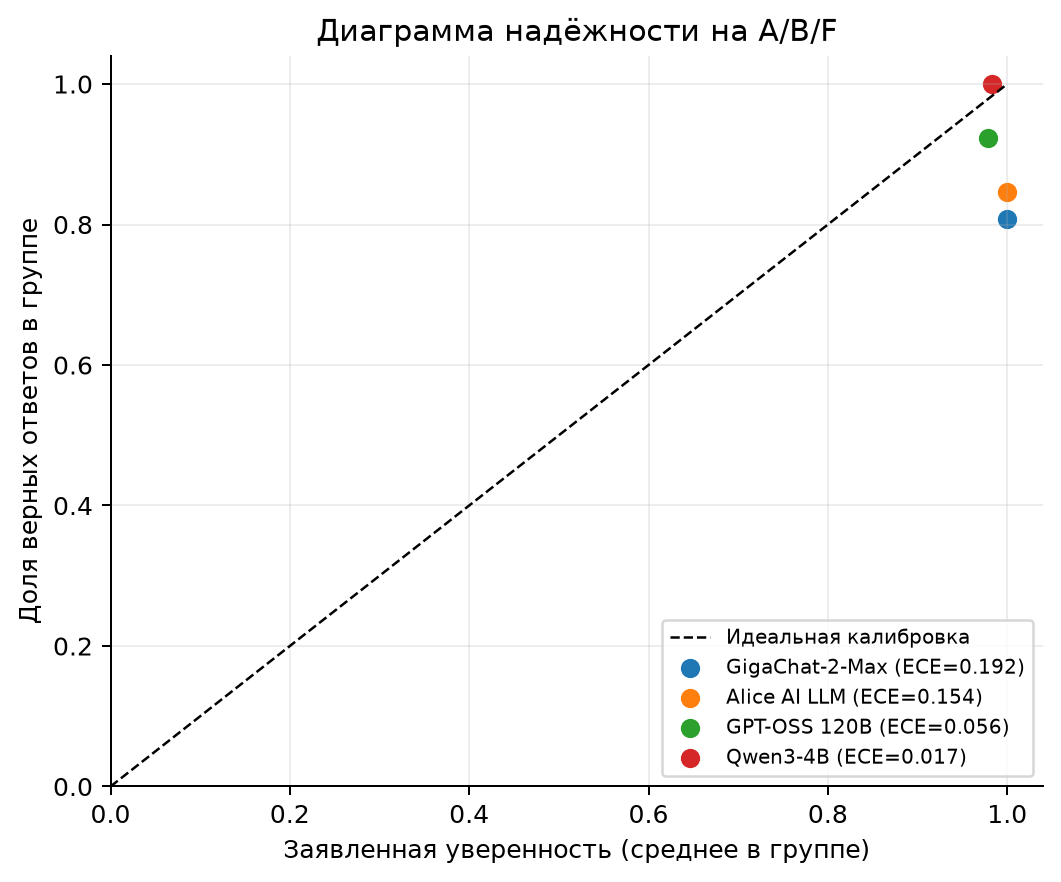

In [14]:
calibration, bins = view.calibration_tables(bundle)
show_table(calibration, 'calibration')
show_figure(view.plot_calibration(bins, calibration), 'reliability')

## 10. Тип E: LLM как классификатор (Breast Cancer Wisconsin, 100 тестовых строк)

Положительный класс 1 — malignant. Разбиение и вложенные демонстрации 5 ⊂ 20
зафиксированы в `data/e_split.json`. Все 30 признаков передаются без округления.
Невалидный ответ штрафуется как ошибка, valid rate показывается отдельно.

In [15]:
split = lab.read_json(lab.DATA / 'e_split.json')
baselines = pd.read_csv(lab.DATA / 'e_baselines.csv')
show_table(baselines, 'e_baselines')
show_table(classification, 'e_metrics')
print('Тестовых строк:', len(split['test']))
print('Демонстрации вложены:', set(split['train5']) <= set(split['train20']))

,model,shots,f1,balanced_accuracy,accuracy,valid_rate,fit_predict_s,f1_ci_low,f1_ci_high,balanced_accuracy_ci_low,balanced_accuracy_ci_high,accuracy_ci_low,accuracy_ci_high
0,LogisticRegression,5,0.7619,0.8134,0.80,1.0,0.0173,0.6753,0.8434,0.7378,0.8857,0.7300,0.87
1,GaussianNB,5,0.2727,0.5731,0.68,1.0,0.0034,0.1000,0.4255,0.5167,0.6351,0.6398,0.73
2,LogisticRegression,20,0.9600,0.9706,0.97,1.0,0.0070,0.9067,1.0000,0.9300,1.0000,0.9300,1.00
3,GaussianNB,20,0.8824,0.8975,0.92,1.0,0.0033,0.7935,0.9577,0.8298,0.9595,0.8600,0.97
4,Always frequent class,20,0.0000,0.5000,0.63,1.0,NaN,0.0000,0.0000,0.5000,0.5000,0.6300,0.63


,модель,примеров,получено,ожидается,статус,F1,balanced accuracy,accuracy,valid rate,F1 ДИ снизу,F1 ДИ сверху,BA ДИ снизу,BA ДИ сверху,обрывов
0,GigaChat-2-Max,0,100,100,готово,0.0000,0.0000,0.00,0.00,0.0000,0.0000,0.0000,0.0000,0
1,GigaChat-2-Max,5,100,100,готово,0.1474,0.1898,0.19,0.23,0.0449,0.2353,0.1096,0.2678,0
2,GigaChat-2-Max,20,100,100,готово,0.6437,0.7038,0.69,0.82,0.5454,0.7381,0.6179,0.7919,1
3,Alice AI LLM,0,100,100,готово,0.5294,0.4865,0.36,0.97,0.5075,0.5401,0.4595,0.5000,0
4,Alice AI LLM,5,100,100,готово,0.7789,0.8333,0.79,1.00,0.7255,0.8409,0.7778,0.8889,0
5,Alice AI LLM,20,100,100,готово,0.7957,0.8492,0.81,1.00,0.7400,0.8605,0.7937,0.9048,0
6,GPT-OSS 120B · Groq,0,100,100,готово,0.7126,0.7681,0.75,0.88,0.6222,0.7912,0.6823,0.8405,0
7,GPT-OSS 120B · Groq,5,100,100,готово,0.8090,0.8595,0.83,1.00,0.7347,0.8706,0.7881,0.9127,0
8,GPT-OSS 120B · Groq,20,100,100,готово,0.8485,0.8704,0.90,1.00,0.7333,0.9296,0.7894,0.9380,0
9,Qwen3 4B · локально,0,100,100,готово,0.3898,0.3505,0.28,0.67,0.3009,0.4716,0.2615,0.4419,1


Тестовых строк: 100
Демонстрации вложены: True


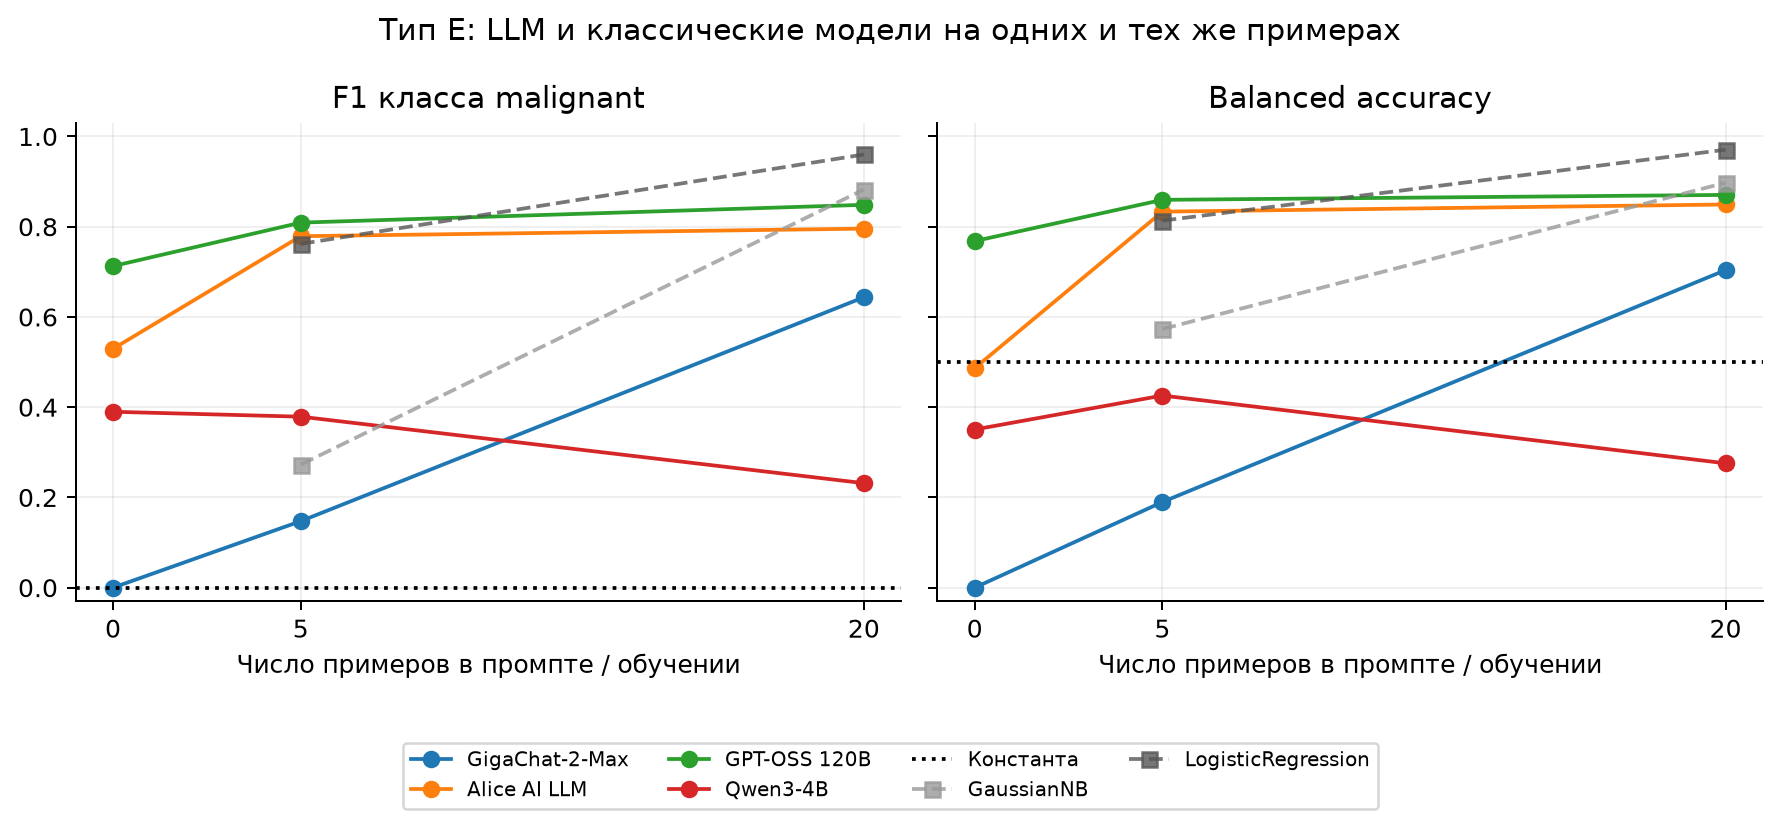

In [16]:
show_figure(view.plot_classification(classification, baselines), 'e_comparison')

In [17]:
print('SHA-256 данных:', split['dataset_sha256'])
print('Пересечение теста и демонстраций:', set(split['test']) & set(split['train20']))

SHA-256 данных: 3019c221882c9c756a9b1c76da7ad72cf606ffe8e51791044aeaadeb33efbd12
Пересечение теста и демонстраций: set()


## 11. Цена и скорость

Денежная оценка — номинальная по сохранённым датированным тарифам, а не списание
из бесплатной квоты. Alice: 500 ₽ за миллион входящих и 1200 ₽ за миллион выходящих токенов
(синхронный режим, источник и дата сохранены в tariffs.json).
Локальная денежная стоимость Qwen не оценена. Память — сохранённый снимок
Ollama, а не пиковое потребление процесса.

,модель,часть,получено ответов,"API задержка средняя, с",токенов на ответ,"номинальная стоимость, ₽",₽ за верный ответ банка,тариф
0,GigaChat-2-Max,bank,36,4.2466,388.4167,9.0890,0.3366,из tariffs.json
1,GigaChat-2-Max,E,300,4.2319,2609.9200,508.9344,NaN,из tariffs.json
2,Alice AI LLM,bank,36,2.7502,390.5278,11.4913,0.4996,из tariffs.json
3,Alice AI LLM,E,300,1.6587,2524.5567,399.0395,NaN,из tariffs.json
4,GPT-OSS 120B · Groq,bank,36,1.4086,683.8056,0.7975,0.0249,из tariffs.json
5,GPT-OSS 120B · Groq,E,300,1.2888,2187.0300,11.4999,NaN,из tariffs.json
6,Qwen3 4B · локально,bank,36,17.0151,2467.8611,NaN,NaN,не подтверждён / локальная модель
7,Qwen3 4B · локально,E,300,27.3922,5792.9667,NaN,NaN,не подтверждён / локальная модель


,модель,дата снимка,"память модели, байт","VRAM, байт","VRAM, ГиБ",контекст
0,qwen3:4b,2026-11-18T11:10:07.745799+00:00,5102307901,5102307901,4.7519,16384


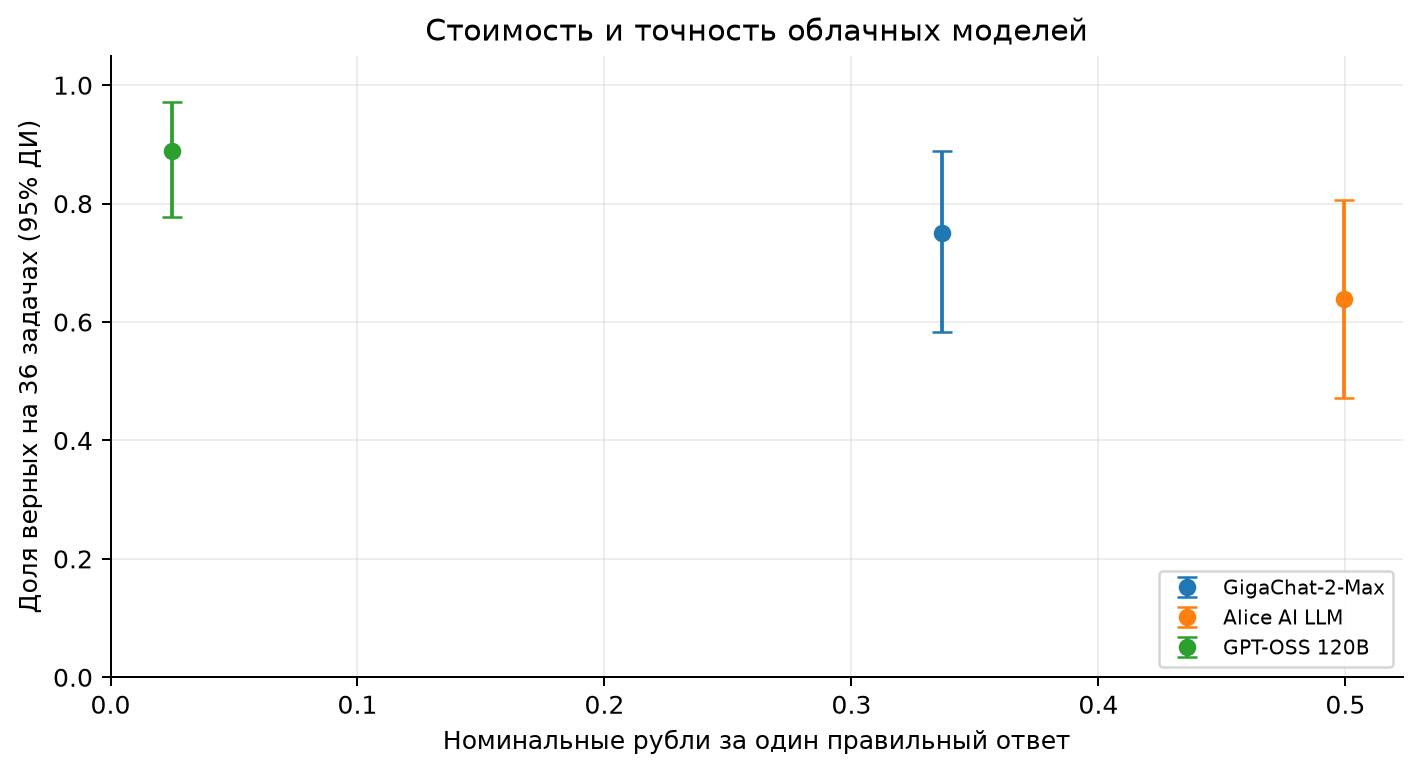

In [18]:
costs = view.cost_latency(bundle)
show_table(costs, 'costs')
resources = view.local_resources()
show_table(resources, 'local_resources')
show_figure(view.plot_cost_accuracy(costs, accuracy), 'cost_accuracy')

## 12. Гипотеза H1 (группа 1): изменённые числа

Восемь заранее заданных пар A/F. Проверяем разность accuracy(A) − accuracy(F)
и точный парный тест Макнемара; поправка Holm по четырём моделям.

,model,delta,accuracy_a,accuracy_f,only_a,only_f,ci,p,pairs,p_holm,status
0,GPT-OSS 120B · Groq,0.000,0.875,0.875,0,0,"(0.0, 0.0)",1.00,8,1.0,данных недостаточно
1,GigaChat-2-Max,0.375,0.875,0.500,3,0,"(0.125, 0.75)",0.25,8,1.0,данных недостаточно
2,Qwen3 4B · локально,0.000,1.000,1.000,0,0,"(0.0, 0.0)",1.00,8,1.0,данных недостаточно
3,Alice AI LLM,0.000,0.750,0.750,2,2,"(-0.5, 0.5)",1.00,8,1.0,данных недостаточно


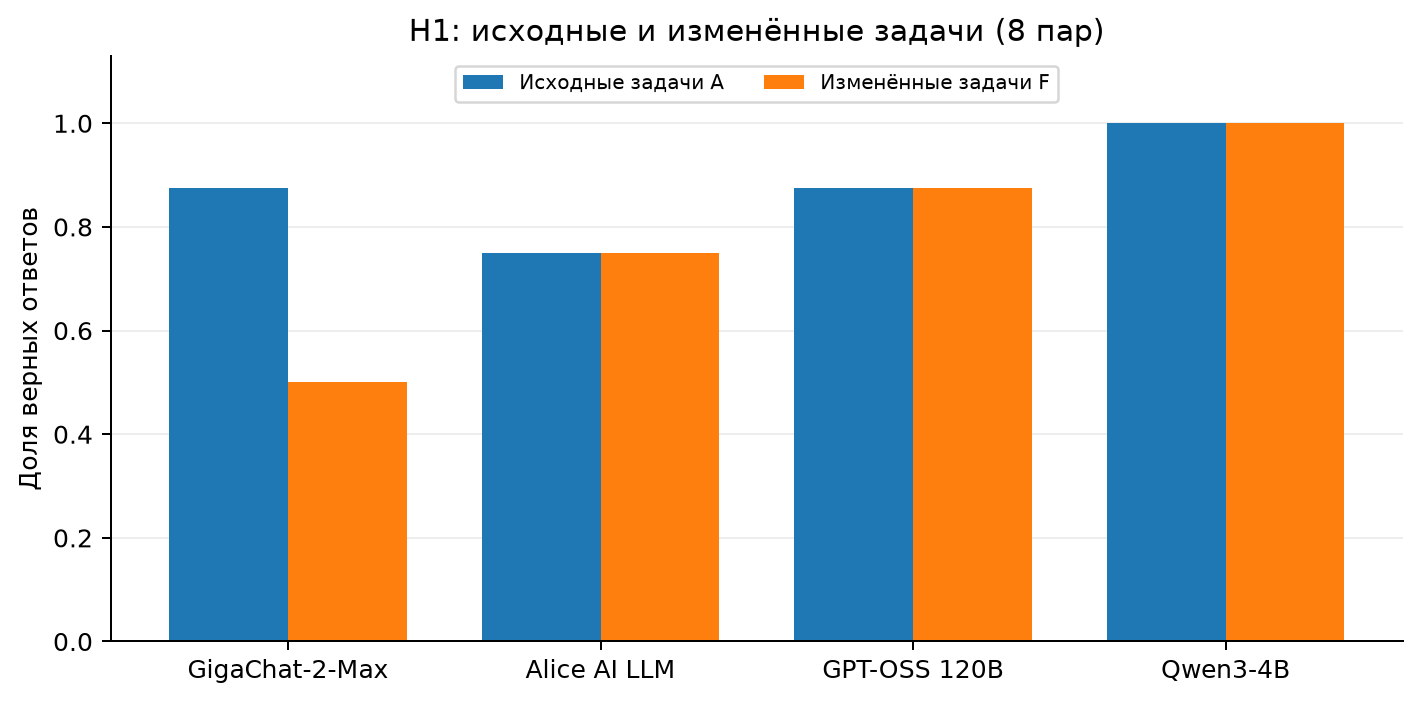

H1: статистической поддержки нет у всех четырёх моделей; прогноз не получил подтверждения.


In [19]:
hypotheses = view.hypothesis_results(bundle)
show_table(view.hypothesis_table(hypotheses, 'H1'), 'h1')
show_figure(view.plot_hypothesis(hypotheses, 'H1'), 'h1')
print('H1: статистической поддержки нет у всех четырёх моделей; прогноз не получил подтверждения.')

## 13. Гипотеза H5 (группа 2): размер модели

Разрыв — средняя accuracy трёх больших моделей минус accuracy Qwen.
Проверяем разность разрывов на A и B, бутстреп внутри типов.

,gap_A,gap_B,large_A,local_A,large_B,local_B,difference,ci,status
0,-0.1667,0.0,0.8333,1.0,1.0,1.0,-0.1667,"[-0.2917, -0.0417]",противоречие


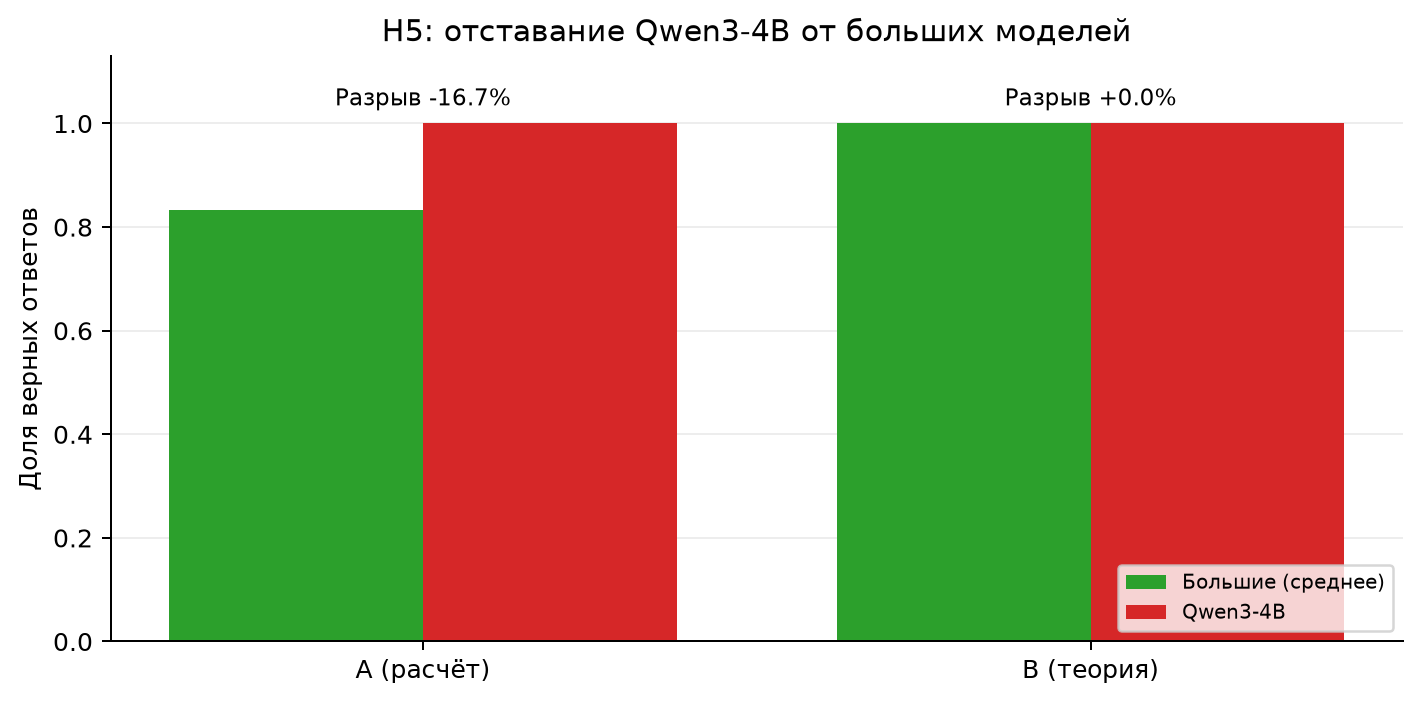

H5: разность −0.167; 95% ДИ [−0.292; −0.042]. Эффект противоположен прогнозу.


In [20]:
show_table(view.hypothesis_table(hypotheses, 'H5'), 'h5')
show_figure(view.plot_hypothesis(hypotheses, 'H5'), 'h5')
print('H5: разность −0.167; 95% ДИ [−0.292; −0.042]. Эффект противоположен прогнозу.')

## 14. Гипотеза H10 (группа 3): завышенная уверенность

Разность — средняя уверенность минус точность на том же подмножестве A/B/F.
Кластерный бутстреп учитывает пары A/F. Анализ этой реализации H10 обозначен
как исследовательский: выводы относятся к принятой процедуре калибровки.

,model,delta,ci,ece,confidence_coverage,status,exploratory
0,GPT-OSS 120B · Groq,0.0558,"(-0.0325, 0.222)",0.0558,1.0000,данных недостаточно,True
1,GigaChat-2-Max,0.1923,"(0.04, 0.3462)",0.1923,1.0000,поддержана,True
2,Qwen3 4B · локально,-0.0167,"(-0.028, -0.0071)",0.0167,0.9231,противоречие,True
3,Alice AI LLM,0.1538,"(0.0385, 0.2692)",0.1538,1.0000,поддержана,True


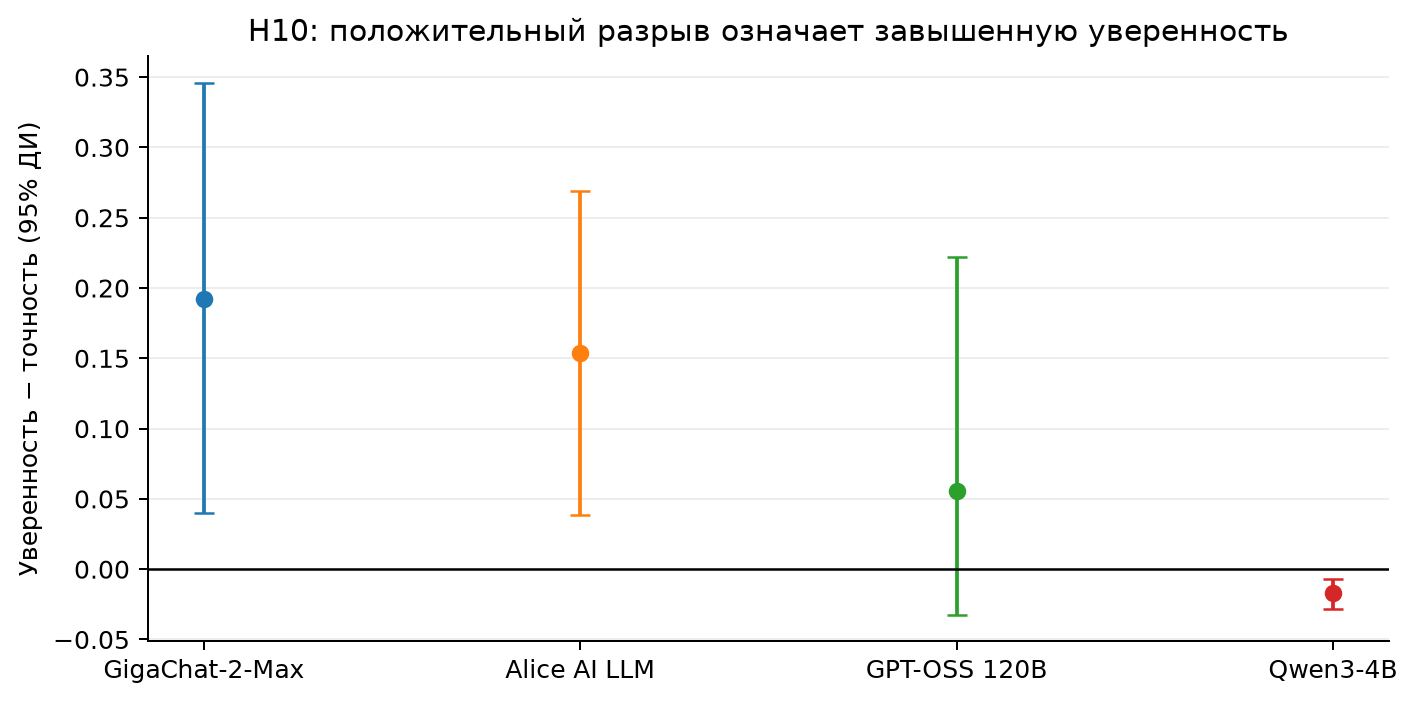

,request_id,model,task_id,quote,category,expected,explanation,confidence_reported
0,4ffb7122-a97f-4693-a123-b26a657fde26,Alice AI LLM,A02,ОТВЕТ: 0.057,Вычислительная ошибка при правильной общей формуле,0.1212,"Для левого узла G=1-(35/37)^2-(2/37)^2=0.1022644, а не 0.189. Для правого G=80/169=0.4733728, а ...",100
1,f777333c-f0ba-448e-bb45-8354d9b5c645,Alice AI LLM,A03,"ОТВЕТ: [0.96, 0.75, 0.6, 0.6666666666666666]",Ошибка подстановки или арифметики accuracy,"[0.97, 0.75, 0.6, 0.6667]","В обосновании приведена правильная формула accuracy, но (30+940)/(30+10+20+940)=970/1000=0.97. Д...",100
2,be17fee9-708a-4da7-a44b-59ff043c4e32,GigaChat-2-Max,A08,Сумма квадратов равна 8/9 * 3 = 8/3 ≈ 2.67,Неверное вычисление расстояний до центроида,"[0.6667, 0.6667, 5.3333]","Центроид (2/3,2/3) верен. Квадрат расстояния от (0,0) равен 8/9, но от (2,0) и (0,2) — по 20/9. ...",100
3,81faf9eb-0d5b-4c1d-bae1-d2120aff01aa,GigaChat-2-Max,F02,ОТВЕТ: 0.46,Неверный числовой итог при правильной записанной формуле,0.1633,"G_parent=0.48, G_left=5/18, G_right=3/8. Взвешенная дочерняя неоднородность равна (3/5)*(5/18)+(...",100
4,3f56f0a0-5537-47be-b660-43a10d35ab58,GigaChat-2-Max,F12,"ОТВЕТ: [1, 1, 14]",Арифметическая ошибка суммы квадратов,"[1, 1, 12]","Центроид (1,1) верен. В самом ответе записано правильное выражение суммы: 1+1+4+1+1+4, однако он...",100


H10 поддержана для GigaChat и Alice; для GPT-OSS данных недостаточно; для Qwen — противоположный эффект.
Ограничения: малый банк, один прогон, процедура оценивания из раздела 1, строгий парсер, неоднозначность F06, изменяемые API.


In [21]:
show_table(view.hypothesis_table(hypotheses, 'H10'), 'h10')
show_figure(view.plot_hypothesis(hypotheses, 'H10'), 'h10')
errors = view.verified_errors(bundle)
show_table(errors, 'verified_errors')
print('H10 поддержана для GigaChat и Alice; для GPT-OSS данных недостаточно; для Qwen — противоположный эффект.')
print('Ограничения: малый банк, один прогон, процедура оценивания из раздела 1, строгий парсер, неоднозначность F06, изменяемые API.')